# Exploratory Data Analysis
Dataset: Food Nutrition and Calories Dataset (Kaggle). Task: regression, predict `calories` (kcal) from five macronutrients.

**Rule:** every figure must be followed by a written finding or decision. Fill in each *Finding* cell after you look at the plot.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style("whitegrid")

DATA_PATH = next(
    p for p in [Path("data/original/calorie_dataset.csv"),
                Path("../data/original/calorie_dataset.csv"),
                Path("calorie_dataset.csv")]
    if p.exists()
)
OUT_ROOT = Path("..") if Path("../data").exists() else Path(".")

df = pd.read_csv(DATA_PATH)
FEATURES = ["protein_g", "carbs_g", "fat_g", "fiber_g", "sugar_g"]
TARGET = "calories"
cols = FEATURES + [TARGET]
df.head()

,protein_g,carbs_g,fat_g,fiber_g,sugar_g,calories,calorie_class
0,22.5,65.2,13.7,9.9,26.7,479.0,medium
1,15.9,20.7,16.8,7.6,15.0,316.0,low
2,28.3,62.4,14.5,10.8,15.3,524.0,medium
3,23.3,18.6,7.9,17.0,0.2,250.0,low
4,30.8,55.1,31.9,12.5,7.2,602.0,medium


## 1. Dimensions, data types, data quality of dataset

In [13]:
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
print("\nNegative values per numeric column:\n", (df[cols] < 0).sum())
print("\ncalorie_class labels:\n", df["calorie_class"].value_counts())
df.describe().T

Shape: (5000, 7)

Dtypes:
 protein_g        float64
carbs_g          float64
fat_g            float64
fiber_g          float64
sugar_g          float64
calories         float64
calorie_class        str
dtype: object

Missing values:
 protein_g        0
carbs_g          0
fat_g            0
fiber_g          0
sugar_g          0
calories         0
calorie_class    0
dtype: int64

Duplicates: 0

Negative values per numeric column:
 protein_g    0
carbs_g      0
fat_g        0
fiber_g      0
sugar_g      0
calories     0
dtype: int64

calorie_class labels:
 calorie_class
medium    3589
low       1248
high       163
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
protein_g,5000.0,25.07672,9.907564,0.0,18.4,25.10,31.700,64.3
carbs_g,5000.0,49.85042,20.071407,0.0,36.3,49.65,63.525,120.6
fat_g,5000.0,20.10528,7.933298,0.0,14.7,20.10,25.400,47.4
fiber_g,5000.0,8.10362,3.923217,0.0,5.3,8.10,10.800,25.9
sugar_g,5000.0,15.08898,9.298863,0.0,8.0,14.90,21.500,51.1
calories,5000.0,480.45580,117.948845,56.0,400.0,480.00,561.250,975.0


no missing values, no duplicates, no negative values, so no imputation or row removal needed

`calorie_class` is derived from `calories` so it is dropped to prevent leakage.

## 2. Univariate distributions

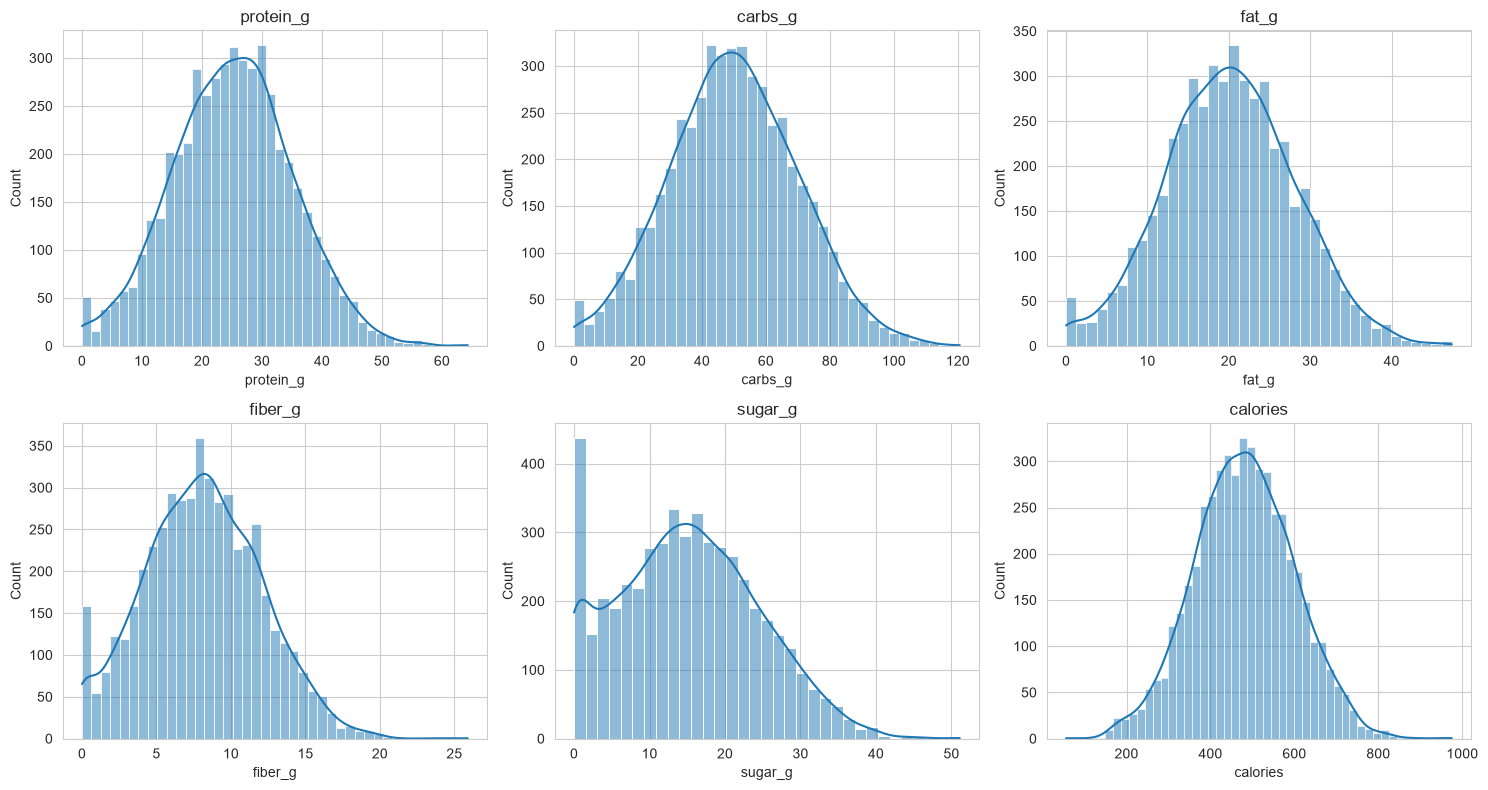

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

predictors & target follow a consistent trend, a bell-curve signaling a normal distribution of values

## 3. Correlation analysis

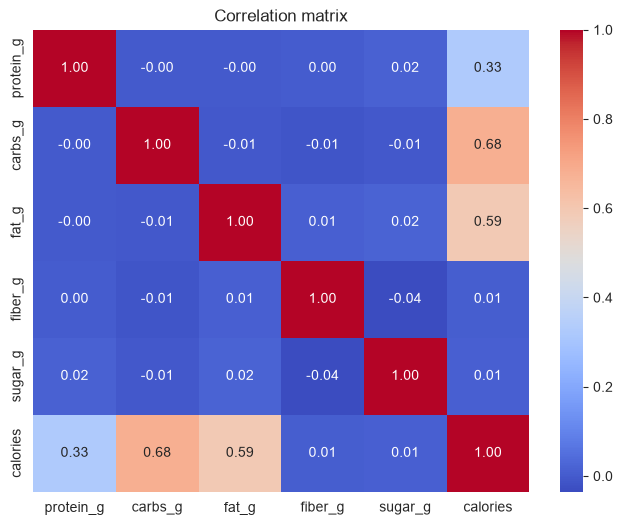

In [15]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation matrix")
plt.show()

protein, carbs, & fat is heavily related to calories

on the meantime fiber & sugar seem to be less 'important'

## 4. Feature vs. target relationships

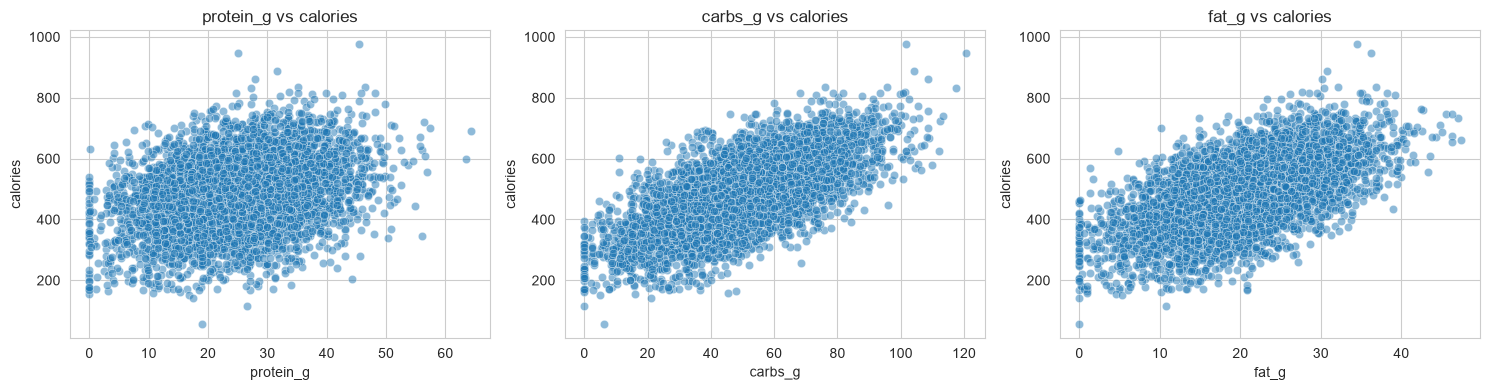

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["protein_g", "carbs_g", "fat_g"]):
    sns.scatterplot(data=df, x=col, y=TARGET, ax=ax, alpha=0.5)
    ax.set_title(f"{col} vs calories")
plt.tight_layout()
plt.show()

a consistent upward trend is seen, if a feature variable rises, so does the target variable

## 5. Outlier investigation

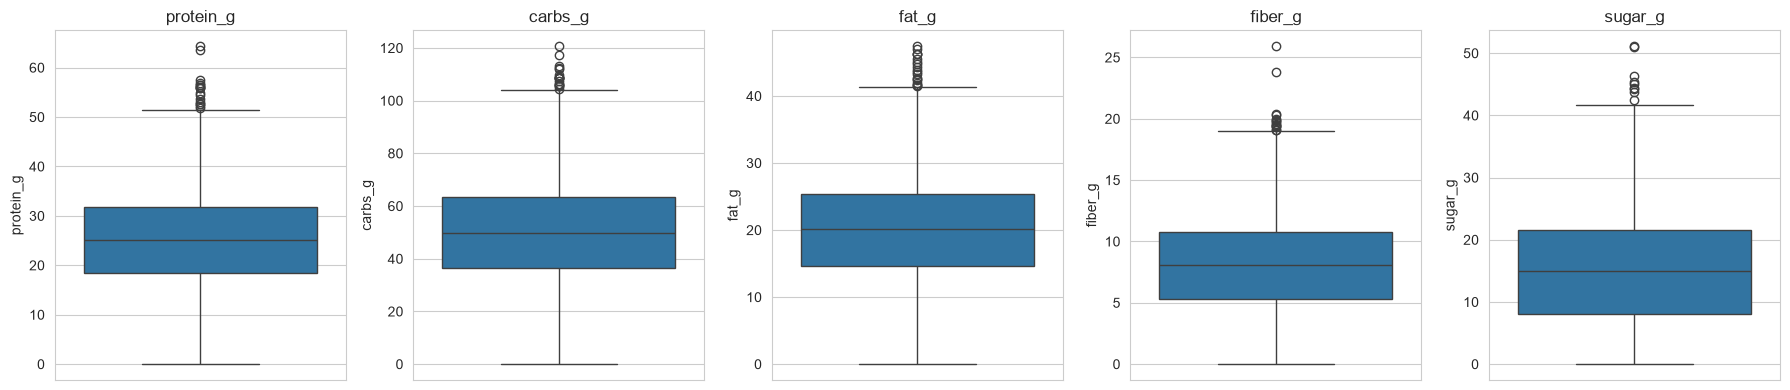

protein_g : 18 points outside 1.5*IQR
carbs_g   : 18 points outside 1.5*IQR
fat_g     : 19 points outside 1.5*IQR
fiber_g   : 15 points outside 1.5*IQR
sugar_g   : 9 points outside 1.5*IQR
calories  : 22 points outside 1.5*IQR


In [17]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, col in zip(axes, FEATURES):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

for col in FEATURES + [TARGET]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:10s}: {n_out} points outside 1.5*IQR")

so long as extreme values are non-negative and physically achievable, is it kept in the dataset

## 6. Save the processed dataset

In [18]:
df_processed = df[cols]     
(OUT_ROOT / "data" / "processed").mkdir(parents=True, exist_ok=True)
df_processed.to_csv(OUT_ROOT / "data" / "processed" / "calorie_dataset_processed.csv", index=False)

print("Original shape :", df.shape)
print("Processed shape:", df_processed.shape)
print("Columns        :", df_processed.columns.tolist())
print("Missing values :", df_processed.isnull().sum().sum())
print("Duplicates     :", df_processed.duplicated().sum())

Original shape : (5000, 7)
Processed shape: (5000, 6)
Columns        : ['protein_g', 'carbs_g', 'fat_g', 'fiber_g', 'sugar_g', 'calories']
Missing values : 0
Duplicates     : 0


## EDA findings summary
_Write 4-6 bullet points linking each finding to a decision (preprocessing, algorithm choice, metric)._
- no missing values, duplicates, no negative values = no imputation / record removal needed
- a bell-curve signaling a normal distribution of values
- protein, carbs, & fat is heavily related to calories, on the other hand fiber & sugar seem to be less 'important'
- a consistent upward trend is seen, if a feature variable rises, so does the target variable
- so long as extreme values are non-negative and physically achievable, is it kept in the dataset

# PREPROCESSING
Standardization of the five numeric features (protein_g, carbs_g, fat_g, fiber_g, sugar_g) using StandardScaling inside a scikit-learn pipline with a ColumnTransformer, fitted only on training data and, within cross-validation, only on the training portion of each fold. Prevents data leakage into training. Mostly done for LinearRegression. Data was pre-prcoessed the same exact way for DecisionTree & RandomForest. 

# DATA SPLIT
80/20 split, 80% training, 20% test (random_state = 42)

# ALGORITHM CHOICE
1. LINEAR REGRESSION - eda showed a linear relationship between the feature variables & the target variable, hence it was a good fit. 
2. DECISION TREE REGRESSOR - mostly used to test whether a non-linear model does better. Unlike Linear Regression, a tree can capture threshold effects and interactions between macros without manual feature engineering, while remaining fully interpretable through its splits. Its main risk is overfitting, so hyperparameters were utilized:
GridSearchCV over a 24-point grid: max_depth ∈ {3, 5, 7, 10, None}, min_samples_split ∈ {2, 5, 10}, min_samples_leaf ∈ {1, 2, 4}, max_features ∈ {None, "sqrt", "log2"}
3. RANDOM FOREST REGRESSOR - builds many trees on random subsets of the data & averages their predictions, which reduces the overfitting problem of the previous algorithm, a single Decision Tree. To keep it fair, the same tunig framework was given.
GridSearchCV over a 24-point grid (n_estimators ∈ {100, 200}, max_depth ∈ {5, 10, None}, min_samples_leaf ∈ {1, 2}, max_features ∈ {"sqrt", "log2"}

# METRIC
- RMSE:  it is expressed in the same units as the target variable (calories), penalises large errors more heavily than small ones, and is therefore the most appropriate choice. It was also used as the scoring function inside every GridSearchCV call, so model selection and final evaluation optimise the same objective and the reported numbers are directly comparable across the three algorithms. MAE, R², Residual Analysis & Error Distribution are used as suporting metrics rather than the primary metric.